In [16]:
!pip install -q tensorflow matplotlib seaborn scikit-learn pillow

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

from PIL import Image

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU: []


In [18]:
from datasets import load_dataset

dataset = load_dataset(
    "dwb2023/cnmc-leukemia-2019"
)

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['subject_id', 'image_number', 'cell_count', 'image', 'label', 'class_label', 'fold', 'original_image_name', 'relative_file_path'],
        num_rows: 10661
    })
})


In [19]:
print(dataset["train"].features)
print(dataset["train"][0])

Output hidden; open in https://colab.research.google.com to view.

In [20]:
data = dataset["train"]

metadata = pd.DataFrame({
    "subject_id": data["subject_id"],
    "label": data["label"],
    "class_label": data["class_label"],
    "fold": data["fold"],
    "original_image_name": data["original_image_name"],
    "relative_file_path": data["relative_file_path"]
})

print(metadata.head())

  subject_id   label class_label  fold original_image_name  \
0          1  cancer         all     0   UID_1_1_1_all.bmp   
1          1  cancer         all     0  UID_1_10_1_all.bmp   
2          1  cancer         all     0  UID_1_10_2_all.bmp   
3          1  cancer         all     0  UID_1_10_3_all.bmp   
4          1  cancer         all     0  UID_1_10_4_all.bmp   

              relative_file_path  
0   fold_0/all/UID_1_1_1_all.bmp  
1  fold_0/all/UID_1_10_1_all.bmp  
2  fold_0/all/UID_1_10_2_all.bmp  
3  fold_0/all/UID_1_10_3_all.bmp  
4  fold_0/all/UID_1_10_4_all.bmp  


In [21]:
print(metadata["label"].value_counts())
print(metadata["class_label"].value_counts())

label
cancer     7272
healthy    3389
Name: count, dtype: int64
class_label
all    7272
hem    3389
Name: count, dtype: int64


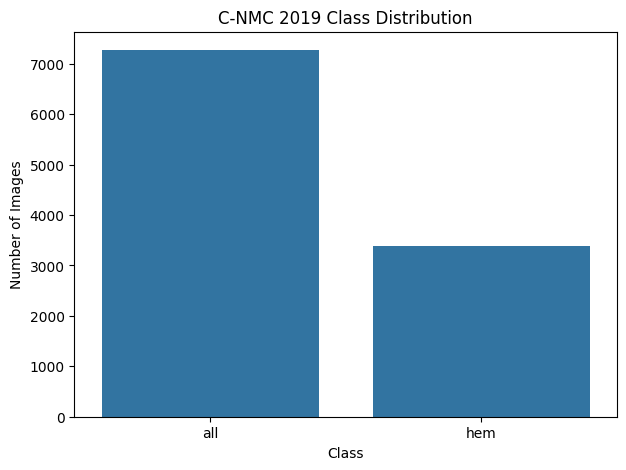

In [22]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=metadata,
    x="class_label"
)

plt.title("C-NMC 2019 Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

Saving Chronic_lymphocytic_leukemia.jpg to Chronic_lymphocytic_leukemia.jpg
Uploaded file: Chronic_lymphocytic_leukemia.jpg


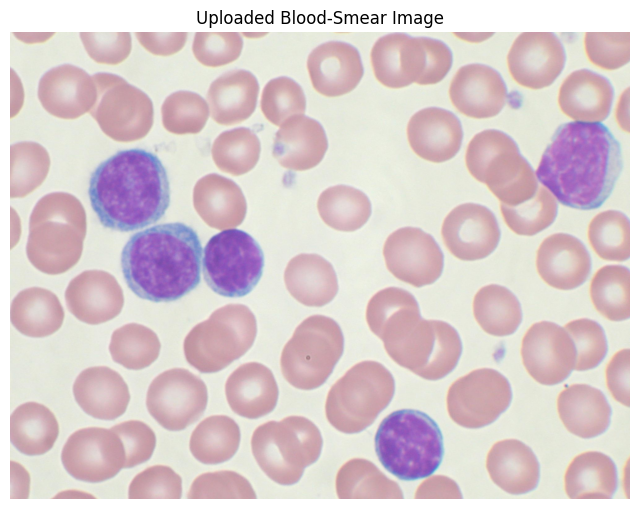

Image size: (2004, 1510)
Image mode: RGB


In [23]:
# UPLOAD AND DISPLAY A BLOOD-SMEAR IMAGE

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

# Upload image
uploaded = files.upload()

# Check if any file was uploaded
if not uploaded:
    print("No file uploaded. Please run the cell again and select an image.")
else:
    # Get uploaded filename safely
    image_path = list(uploaded.keys())[0]
    print("Uploaded file:", image_path)

    # Open image
    image = Image.open(image_path).convert("RGB")

    # Display
    plt.figure(figsize=(8, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Uploaded Blood-Smear Image")
    plt.show()

    # Display image information
    print("Image size:", image.size)
    print("Image mode:", image.mode)

In [24]:
# FIX HUGGING FACE IMAGE DECODING

from datasets import Image as HFImage

# Tell Hugging Face to decode the image automatically
data = data.cast_column(
    "image",
    HFImage()
)

print("Image column converted successfully.")
print(data.features["image"])

Image column converted successfully.
Image(mode=None, decode=True)


In [25]:
# DATASET INFORMATION

print("Number of images:", len(data))

print("\nDataset features:")
print(data.features)

print("\nFirst sample metadata:")

sample = data[0]

for key, value in sample.items():

    if key != "image":
        print(key, ":", value)

Number of images: 10661

Dataset features:
{'subject_id': Value('string'), 'image_number': Value('int64'), 'cell_count': Value('int64'), 'image': Image(mode=None, decode=True), 'label': Value('string'), 'class_label': Value('string'), 'fold': Value('int64'), 'original_image_name': Value('string'), 'relative_file_path': Value('string')}

First sample metadata:
subject_id : 1
image_number : 1
cell_count : 1
label : cancer
class_label : all
fold : 0
original_image_name : UID_1_1_1_all.bmp
relative_file_path : fold_0/all/UID_1_1_1_all.bmp


In [26]:
# CREATE METADATA

metadata = pd.DataFrame({

    "dataset_index": np.arange(len(data)),

    "subject_id": data["subject_id"],

    "label": data["label"],

    "class_label": data["class_label"],

    "fold": data["fold"],

    "original_image_name":
        data["original_image_name"],

    "relative_file_path":
        data["relative_file_path"]
})

print(metadata.head())

print("\nTotal images:")
print(len(metadata))

   dataset_index subject_id   label class_label  fold original_image_name  \
0              0          1  cancer         all     0   UID_1_1_1_all.bmp   
1              1          1  cancer         all     0  UID_1_10_1_all.bmp   
2              2          1  cancer         all     0  UID_1_10_2_all.bmp   
3              3          1  cancer         all     0  UID_1_10_3_all.bmp   
4              4          1  cancer         all     0  UID_1_10_4_all.bmp   

              relative_file_path  
0   fold_0/all/UID_1_1_1_all.bmp  
1  fold_0/all/UID_1_10_1_all.bmp  
2  fold_0/all/UID_1_10_2_all.bmp  
3  fold_0/all/UID_1_10_3_all.bmp  
4  fold_0/all/UID_1_10_4_all.bmp  

Total images:
10661


In [27]:
# ============================================
# CHECK CLASS DISTRIBUTION
# ============================================

print("Label values:")
print(metadata["label"].value_counts())

print("\nClass labels:")
print(metadata["class_label"].value_counts())
def convert_label(value):

    value = str(value).lower().strip()

    # Leukemia / ALL
    if value in [
        "all",
        "cancer",
        "leukemia",
        "1",
        "1.0"
    ]:
        return 1

    # Normal / HEM
    elif value in [
        "hem",
        "normal",
        "healthy",
        "0",
        "0.0"
    ]:
        return 0

    else:
        raise ValueError(
            f"Unknown label found: {value}"
        )


metadata["numeric_label"] = (
    metadata["class_label"]
    .apply(convert_label)
)

print(
    metadata[
        [
            "class_label",
            "numeric_label"
        ]
    ].head(20)
)

Label values:
label
cancer     7272
healthy    3389
Name: count, dtype: int64

Class labels:
class_label
all    7272
hem    3389
Name: count, dtype: int64
   class_label  numeric_label
0          all              1
1          all              1
2          all              1
3          all              1
4          all              1
5          all              1
6          all              1
7          all              1
8          all              1
9          all              1
10         all              1
11         all              1
12         all              1
13         all              1
14         all              1
15         all              1
16         all              1
17         all              1
18         all              1
19         all              1


In [28]:
# ============================================
# FINAL CLASS DISTRIBUTION
# ============================================

print(
    metadata["numeric_label"]
    .value_counts()
)

print("\n0 = Normal")
print("1 = Leukemia")

numeric_label
1    7272
0    3389
Name: count, dtype: int64

0 = Normal
1 = Leukemia


In [29]:
# ============================================
# PATIENT-LEVEL TRAIN/TEST SPLIT
# ============================================

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_indices, test_indices = next(
    splitter.split(
        metadata,
        groups=metadata["subject_id"]
    )
)

train_val_metadata = (
    metadata.iloc[
        train_val_indices
    ]
    .reset_index(drop=True)
)

test_metadata = (
    metadata.iloc[
        test_indices
    ]
    .reset_index(drop=True)
)

print(
    "Training + Validation images:",
    len(train_val_metadata)
)

print(
    "Testing images:",
    len(test_metadata)
)

Training + Validation images: 9315
Testing images: 1346


In [30]:
# ============================================
# PATIENT-LEVEL TRAIN/VALIDATION SPLIT
# ============================================

splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, val_indices = next(
    splitter_val.split(
        train_val_metadata,
        groups=train_val_metadata["subject_id"]
    )
)

train_metadata = (
    train_val_metadata
    .iloc[train_indices]
    .reset_index(drop=True)
)

val_metadata = (
    train_val_metadata
    .iloc[val_indices]
    .reset_index(drop=True)
)

print(
    "Training images:",
    len(train_metadata)
)

print(
    "Validation images:",
    len(val_metadata)
)

print(
    "Testing images:",
    len(test_metadata)
)

Training images: 7659
Validation images: 1656
Testing images: 1346


In [31]:
# ============================================
# CHECK FOR PATIENT DATA LEAKAGE
# ============================================

train_subjects = set(
    train_metadata["subject_id"]
)

val_subjects = set(
    val_metadata["subject_id"]
)

test_subjects = set(
    test_metadata["subject_id"]
)

print(
    "Train ∩ Validation:",
    train_subjects.intersection(
        val_subjects
    )
)

print(
    "Train ∩ Test:",
    train_subjects.intersection(
        test_subjects
    )
)

print(
    "Validation ∩ Test:",
    val_subjects.intersection(
        test_subjects
    )
)

Train ∩ Validation: set()
Train ∩ Test: set()
Validation ∩ Test: set()


In [32]:
# ============================================
# IMAGE SETTINGS
# ============================================

IMG_SIZE = 224
BATCH_SIZE = 32

AUTOTUNE = tf.data.AUTOTUNE

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 224
Batch size: 32


In [33]:
# ============================================
# LOAD TRAINING IMAGE
# ============================================

def load_hf_image(
    dataset_index,
    label
):

    # Retrieve image from Hugging Face
    image = data[int(dataset_index)]["image"]

    # Convert to RGB
    image = image.convert("RGB")

    # Resize
    image = image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    # Convert to NumPy
    image = np.array(
        image,
        dtype=np.float32
    )

    return image, np.float32(label)

In [34]:
# ============================================
# CREATE TENSORFLOW GENERATOR
# ============================================

def dataset_generator(metadata_df):

    indices = metadata_df[
        "dataset_index"
    ].values

    labels = metadata_df[
        "numeric_label"
    ].values

    for index, label in zip(
        indices,
        labels
    ):

        image, label = load_hf_image(
            index,
            label
        )

        yield image, label

In [35]:
# ============================================
# CREATE TF DATASETS
# ============================================

output_signature = (

    tf.TensorSpec(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        dtype=tf.float32
    ),

    tf.TensorSpec(
        shape=(),
        dtype=tf.float32
    )
)


train_ds = tf.data.Dataset.from_generator(

    lambda:
        dataset_generator(
            train_metadata
        ),

    output_signature=output_signature
)


val_ds = tf.data.Dataset.from_generator(

    lambda:
        dataset_generator(
            val_metadata
        ),

    output_signature=output_signature
)


test_ds = tf.data.Dataset.from_generator(

    lambda:
        dataset_generator(
            test_metadata
        ),

    output_signature=output_signature
)

In [36]:
# ============================================
# PREPARE DATASETS
# ============================================

train_ds = (
    train_ds
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("TensorFlow datasets created.")

TensorFlow datasets created.


In [37]:
# ============================================
# TEST DATA PIPELINE
# ============================================

images, labels = next(
    iter(train_ds)
)

print(
    "Image batch:",
    images.shape
)

print(
    "Label batch:",
    labels.shape
)

print(
    "First labels:",
    labels[:10].numpy()
)

Image batch: (32, 224, 224, 3)
Label batch: (32,)
First labels: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [38]:
# ============================================
# DATA AUGMENTATION
# ============================================

data_augmentation = keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.05
    ),

    layers.RandomZoom(
        0.10
    ),

    layers.RandomContrast(
        0.10
    )

], name="data_augmentation")

In [39]:
# ============================================
# EFFICIENTNETB0
# ============================================

base_model = EfficientNetB0(

    include_top=False,

    weights="imagenet",

    input_shape=(
        IMG_SIZE,
        IMG_SIZE,
        3
    )
)

base_model.trainable = False

print(
    "EfficientNetB0 loaded."
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded.


In [40]:
# ============================================
# BUILD MODEL
# ============================================

inputs = keras.Input(
    shape=(
        IMG_SIZE,
        IMG_SIZE,
        3
    )
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = keras.Model(
    inputs,
    outputs
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [41]:
# ============================================
# COMPILE MODEL
# ============================================

model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss="binary_crossentropy",

    metrics=[

        "accuracy",

        keras.metrics.Precision(
            name="precision"
        ),

        keras.metrics.Recall(
            name="recall"
        ),

        keras.metrics.AUC(
            name="auc"
        )
    ]
)

print("Model compiled.")

Model compiled.


In [42]:
# ============================================
# CLASS WEIGHTS
# ============================================

from sklearn.utils.class_weight import (
    compute_class_weight
)

classes = np.unique(
    train_metadata["numeric_label"]
)

weights = compute_class_weight(

    class_weight="balanced",

    classes=classes,

    y=train_metadata[
        "numeric_label"
    ]
)

class_weights = {
    int(cls): float(weight)

    for cls, weight in zip(
        classes,
        weights
    )
}

print(
    "Class weights:",
    class_weights
)

Class weights: {0: 1.7203504043126685, 1: 0.7048591938155715}


In [43]:
# ============================================
# CALLBACKS
# ============================================

callbacks = [

    keras.callbacks.EarlyStopping(

        monitor="val_auc",

        mode="max",

        patience=5,

        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.2,

        patience=2,

        min_lr=1e-7
    ),

    keras.callbacks.ModelCheckpoint(

        "/content/best_leukemia_model.keras",

        monitor="val_auc",

        mode="max",

        save_best_only=True
    )
]

In [45]:
# ============================================================
# FIX CORRUPTED / INVALID IMAGES
# ============================================================

from PIL import Image, UnidentifiedImageError
from io import BytesIO

print("Checking dataset for corrupted images...")

valid_indices = []
bad_indices = []

for i in range(len(dataset)):
    try:
        item = dataset[i]
        image_data = item["image"]

        # Case 1: HuggingFace already returned a PIL image
        if isinstance(image_data, Image.Image):
            image_data.convert("RGB").load()

        # Case 2: image is stored as bytes/dictionary
        elif isinstance(image_data, dict):
            if "bytes" in image_data and image_data["bytes"] is not None:
                img = Image.open(BytesIO(image_data["bytes"]))
                img.verify()
            elif "path" in image_data and image_data["path"] is not None:
                img = Image.open(image_data["path"])
                img.verify()
            else:
                raise ValueError("Invalid image dictionary")

        # Case 3: raw bytes
        elif isinstance(image_data, bytes):
            img = Image.open(BytesIO(image_data))
            img.verify()

        else:
            raise ValueError(f"Unknown image type: {type(image_data)}")

        valid_indices.append(i)

    except Exception as e:
        bad_indices.append(i)

print("\nDataset check complete.")
print("Total images :", len(dataset))
print("Valid images :", len(valid_indices))
print("Bad images   :", len(bad_indices))

if bad_indices:
    print("\nBad image indices:")
    print(bad_indices[:20])

Checking dataset for corrupted images...

Dataset check complete.
Total images : 1
Valid images : 0
Bad images   : 1

Bad image indices:
[0]


In [ ]:
# ============================================
# ROBUST GENERATOR & MODEL TRAINING WITH REPEAT
# ============================================

# Redefine the generator to safely skip corrupt or unreadable images
def dataset_generator(metadata_df):
    indices = metadata_df["dataset_index"].values
    labels = metadata_df["numeric_label"].values

    for index, label in zip(indices, labels):
        try:
            image, label = load_hf_image(index, label)
            yield image, label
        except Exception as e:
            # Safely skip unidentified image files or other loading errors
            continue

# Re-create datasets with the robust generator
output_signature = (
    tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
    tf.TensorSpec(shape=(), dtype=tf.float32)
)

# Calculate steps per epoch based on batch size
train_steps = int(np.ceil(len(train_metadata) / BATCH_SIZE))
val_steps = int(np.ceil(len(val_metadata) / BATCH_SIZE))

# Use .repeat() so the generator restarts automatically for each epoch
train_ds = tf.data.Dataset.from_generator(
    lambda: dataset_generator(train_metadata),
    output_signature=output_signature
).shuffle(1000).repeat().batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = tf.data.Dataset.from_generator(
    lambda: dataset_generator(val_metadata),
    output_signature=output_signature
).repeat().batch(BATCH_SIZE).prefetch(AUTOTUNE)

# Start training
history = model.fit(
    train_ds,
    steps_per_epoch=train_steps,
    validation_data=val_ds,
    validation_steps=val_steps,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/15
    229/Unknown 779s 3s/step - accuracy: 0.8325 - auc: 0.7827 - loss: 0.4158 - precision: 0.9149 - recall: 0.8527

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


229/229 ━━━━━━━━━━━━━━━━━━━━ 940s 4s/step - accuracy: 0.7997 - auc: 0.8744 - loss: 0.4599 - precision: 0.9006 - recall: 0.8003 - val_accuracy: 0.6329 - val_auc: 0.7418 - val_loss: 0.6689 - val_precision: 0.6300 - val_recall: 0.2755 - learning_rate: 0.0010
Epoch 2/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 1100s 5s/step - accuracy: 0.7794 - auc: 0.8609 - loss: 0.4888 - precision: 0.8945 - recall: 0.7741 - val_accuracy: 0.6667 - val_auc: 0.7436 - val_loss: 0.6105 - val_precision: 0.6188 - val_recall: 0.5087 - learning_rate: 0.0010
Epoch 3/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 934s 4s/step - accuracy: 0.7886 - auc: 0.8694 - loss: 0.4718 - precision: 0.8999 - recall: 0.7832 - val_accuracy: 0.6787 - val_auc: 0.7497 - val_loss: 0.6082 - val_precision: 0.6266 - val_recall: 0.5554 - learning_rate: 0.0010
Epoch 4/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7701 - auc: 0.7512 - loss: 0.4935 - precision: 0.9187 - recall: 0.7772

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


229/229 ━━━━━━━━━━━━━━━━━━━━ 930s 4s/step - accuracy: 0.8002 - auc: 0.8786 - loss: 0.4566 - precision: 0.9066 - recall: 0.7946 - val_accuracy: 0.6751 - val_auc: 0.7491 - val_loss: 0.6036 - val_precision: 0.6135 - val_recall: 0.5831 - learning_rate: 0.0010
Epoch 5/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 1038s 4s/step - accuracy: 0.7998 - auc: 0.8750 - loss: 0.4645 - precision: 0.9006 - recall: 0.8005 - val_accuracy: 0.6824 - val_auc: 0.7525 - val_loss: 0.6047 - val_precision: 0.6166 - val_recall: 0.6166 - learning_rate: 0.0010
Epoch 6/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 1030s 4s/step - accuracy: 0.7989 - auc: 0.8817 - loss: 0.4488 - precision: 0.9060 - recall: 0.7930 - val_accuracy: 0.6842 - val_auc: 0.7552 - val_loss: 0.6075 - val_precision: 0.6106 - val_recall: 0.6560 - learning_rate: 0.0010
Epoch 7/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 981s 4s/step - accuracy: 0.7856 - auc: 0.8553 - loss: 0.4853 - precision: 0.8914 - recall: 0.7877 - val_accuracy: 0.6830 - val_auc: 0.7553 - val_loss: 0.6021 - val_prec

In [ ]:
# ============================================
# ACCURACY
# ============================================

plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()

plt.show()

In [ ]:
# ============================================
# LOSS
# ============================================

plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training vs Validation Loss"
)

plt.legend()

plt.show()

In [ ]:
# ============================================
# FINE-TUNING
# ============================================

base_model.trainable = True

# Freeze early layers
for layer in base_model.layers[:-30]:

    layer.trainable = False

print(
    "Fine-tuning last 30 layers."
)

In [ ]:
# ============================================
# RECOMPILE FOR FINE-TUNING
# ============================================

model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss="binary_crossentropy",

    metrics=[

        "accuracy",

        keras.metrics.Precision(
            name="precision"
        ),

        keras.metrics.Recall(
            name="recall"
        ),

        keras.metrics.AUC(
            name="auc"
        )
    ]
)

In [ ]:
# ============================================
# FINE-TUNE MODEL
# ============================================

fine_history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=10,

    class_weight=class_weights,

    callbacks=callbacks
)

In [ ]:
# ============================================
# TEST MODEL
# ============================================

results = model.evaluate(
    test_ds
)

for name, value in zip(
    model.metrics_names,
    results
):

    print(
        f"{name}: {value:.4f}"
    )

In [ ]:
# ============================================
# TEST PREDICTIONS
# ============================================

y_true = test_metadata[
    "numeric_label"
].to_numpy()

y_probability = model.predict(
    test_ds
).ravel()

y_pred = (
    y_probability >= 0.5
).astype(int)

print(
    "Predictions generated."
)

In [ ]:
# ============================================
# CLASSIFICATION REPORT
# ============================================

print(
    classification_report(

        y_true,

        y_pred,

        target_names=[
            "Normal",
            "Leukemia"
        ]
    )
)

In [ ]:
# ============================================
# CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    xticklabels=[
        "Normal",
        "Leukemia"
    ],

    yticklabels=[
        "Normal",
        "Leukemia"
    ]
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    "Leukemia Detection Confusion Matrix"
)

plt.show()

In [ ]:
# ============================================
# ROC-AUC
# ============================================

auc_score = roc_auc_score(
    y_true,
    y_probability
)

print(
    f"ROC-AUC: {auc_score:.4f}"
)

In [ ]:
# ============================================
# ROC CURVE
# ============================================

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_probability
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc_score:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve"
)

plt.legend()

plt.show()

In [ ]:
# ============================================
# PRECISION-RECALL CURVE
# ============================================

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision, recall, thresholds = (
    precision_recall_curve(
        y_true,
        y_probability
    )
)

average_precision = (
    average_precision_score(
        y_true,
        y_probability
    )
)

plt.figure(figsize=(7,6))

plt.plot(
    recall,
    precision,
    label=f"AP = {average_precision:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve"
)

plt.legend()

plt.show()

In [ ]:
# ============================================
# FIND GRAD-CAM LAYER
# ============================================

last_conv_layer = None

for layer in reversed(
    base_model.layers
):

    if len(layer.output.shape) == 4:

        last_conv_layer = layer

        break

print(
    "Grad-CAM layer:",
    last_conv_layer.name
)

In [ ]:
# ============================================
# GRAD-CAM
# ============================================

def make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer
):

    grad_model = keras.models.Model(

        inputs=model.inputs,

        outputs=[
            last_conv_layer.output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = (
            grad_model(img_array)
        )

        prediction = predictions[:, 0]

    grads = tape.gradient(
        prediction,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0,1,2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = (
        conv_outputs
        @ pooled_grads[..., tf.newaxis]
    )

    heatmap = tf.squeeze(
        heatmap
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    heatmap /= (
        tf.reduce_max(heatmap)
        + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [ ]:
# ============================================
# PREDICT UPLOADED IMAGE
# ============================================

def predict_uploaded_image(
    image_path
):

    # Open uploaded image
    image = Image.open(
        image_path
    ).convert("RGB")

    # Keep original
    original = np.array(image)

    # Resize
    resized = image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    # NumPy
    img_array = np.array(
        resized,
        dtype=np.float32
    )

    # Add batch dimension
    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    # Model prediction
    probability = model.predict(
        img_array,
        verbose=0
    )[0][0]

    # Grad-CAM
    heatmap = make_gradcam_heatmap(
        img_array,
        model,
        last_conv_layer
    )

    # Resize heatmap
    heatmap_image = Image.fromarray(
        np.uint8(
            heatmap * 255
        )
    )

    heatmap_image = heatmap_image.resize(
        (
            original.shape[1],
            original.shape[0]
        )
    )

    heatmap_array = np.array(
        heatmap_image
    )

    # Prediction
    if probability >= 0.5:

        prediction = "LEUKEMIA"

        confidence = (
            probability * 100
        )

    else:

        prediction = "NORMAL"

        confidence = (
            (1 - probability) * 100
        )

    # Display
    plt.figure(figsize=(15,5))

    # Original
    plt.subplot(1,3,1)

    plt.imshow(original)

    plt.axis("off")

    plt.title(
        "Uploaded Blood-Smear Image"
    )

    # Grad-CAM
    plt.subplot(1,3,2)

    plt.imshow(
        heatmap_array,
        cmap="jet"
    )

    plt.axis("off")

    plt.title(
        "Grad-CAM"
    )

    # Overlay
    plt.subplot(1,3,3)

    plt.imshow(original)

    plt.imshow(
        heatmap_array,
        cmap="jet",
        alpha=0.4
    )

    plt.axis("off")

    plt.title(
        "Grad-CAM Overlay"
    )

    plt.tight_layout()

    plt.show()

    # Result
    print("=" * 55)

    print(
        "LEUKEMIA DETECTION SYSTEM"
    )

    print("=" * 55)

    print(
        f"Prediction : {prediction}"
    )

    print(
        f"Confidence : {confidence:.2f}%"
    )

    print("=" * 55)

In [ ]:
predict_uploaded_image(
    image_path
)

In [ ]:
# ============================================
# SAVE MODEL
# ============================================

MODEL_PATH = (
    "/content/leukemia_efficientnet.keras"
)

model.save(
    MODEL_PATH
)

print(
    "Model saved to:",
    MODEL_PATH
)

In [ ]:
# ============================================
# DOWNLOAD TRAINED MODEL
# ============================================

from google.colab import files

files.download(
    MODEL_PATH
)